In [68]:
# Dataset: ทำนายคนเป็นโรคเบาหวาน [https://www.kaggle.com/datasets/akshaydattatraykhare/diabetes-dataset]
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score


train_origin = pd.read_csv("./d2/train.csv")
val_origin = pd.read_csv('./d2/val.csv')
test_origin = pd.read_csv("./d2/test.csv")


train_df = train_origin.copy()
val_df = val_origin.copy()
test_df = test_origin.copy()




,0,1,2,3,4,5,6,7,8,9
0,2.75,82.5,259.6,144.7,39.13,58.5,10.0,0.1041,10.7,2997645.37
1,3.29,111.5,248.9,77.1,0.00,41.2,0.0,0.1971,18.1,114698.74
2,3.67,111.8,57.7,232.5,14.18,25.0,0.0,0.1667,26.0,92.74
3,1.07,21.3,101.6,178.1,19.45,48.9,0.0,0.1861,0.0,2260.33
4,2.58,71.2,169.9,330.3,17.76,7.5,2.0,0.1147,47.0,258.10
...,...,...,...,...,...,...,...,...,...,...
1912,1.05,30.9,130.5,348.6,27.59,47.6,222.0,0.1174,53.3,98162.30
1913,0.33,20.4,81.3,241.8,21.02,68.9,6.0,0.2036,11.3,374.78
1914,1.83,45.2,108.8,107.7,31.62,59.5,11.0,0.1954,6.9,2139917.39
1915,1.06,52.9,143.0,174.0,32.43,72.5,0.0,0.1852,15.3,4108.18


In [2]:

train_df.shape

(1917, 14)

In [3]:
len(train_df["filename"].unique())

1917

In [4]:
import torch
from torch.utils.data import Dataset
import pandas as pd
from PIL import Image
import os
from torchvision import datasets, transforms



test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),

])

class TestDataset(Dataset):
    def __init__(self, csv_path, image_dir, transform=None,):
        """
        Args:
            csv_path (string): Path to the CSV file.
            image_dir (string): Directory where images are stored.
            question_mapping (dict): A dictionary mapping question text to indices.
                                     Example: {"Building count": 0, "Building density": 1, ...}
            transform ( callable, optional): Optional transform to be applied on images.
        """
        self.csv_path = csv_path
        self.image_dir = image_dir
        self.transform = transform
        self.file = pd.read_csv(self.csv_path)
        self.labels_dict = {filename: [] for filename in self.file["filename"].unique().tolist()}
        self.filenames = self.file["filename"].unique().tolist()
       

    def __len__(self):
        # TODO: Return the total number of images in the dataset
        return len(self.file["filename"].unique().tolist())

    def __getitem__(self, idx):
        # TODO: Get the filename at the current index from self.filenames
        
        # TODO: Load the image from the image_dir using the filename
        # (Hint: You'll need to handle the path correctly)
        
        # TODO: Retrieve the 3 labels from the dictionary using the filename
        # Ensure they are converted to a Torch Tensor
        
        # TODO: Apply the transform to the image if provided
        
        # TODO: Return the image tensor and the labels tensor
        filename = self.filenames[idx]
        # Use os.path.join for safety
        path_file = os.path.join(self.image_dir, filename)
        
        # Use Image directly
        image = Image.open(path_file).convert("RGB")
        
       
        if self.transform is not None:
            image = self.transform(image)
        return {
            "image": image
            }

train_dataset = TestDataset("./d2/train.csv", "./d2/images/", transform=test_transform)
val_dataset = TestDataset("./d2/val.csv", "./d2/images/", transform=test_transform)
test_dataset = TestDataset("./d2/test.csv", "./d2/images/", transform=test_transform)

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [5]:
class CustomLeNet5(nn.Module):
    def __init__(self, input_size=(3, 256, 256), num_classes=4):
        super(CustomLeNet5, self).__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(in_channels=input_size[0], out_channels=32, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
        )

        self.head1 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._get_input_size_fc1(input_size), 256), 
            nn.ReLU(), nn.Dropout(), nn.Linear(256, 128), 
            nn.ReLU(), nn.Dropout(), nn.Linear(128, 10))
        self.head2 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._get_input_size_fc1(input_size), 256), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(256, 128), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(128, 4)
        )
        self.head3 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._get_input_size_fc1(input_size), 256), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(256, 128), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(128, 1)
        )
        
    def _get_input_size_fc1(self, input_shape):
        with torch.no_grad():
            x = torch.zeros(1, *input_shape)
            x = self.extractor(x)
            x = torch.flatten(x, 1)
        return x.size(1)

    def forward(self, x):
        # This is the processed feature map
        shared = self.extractor(x) 
        
        # Pass 'shared' into the heads instead of 'x'
        one = self.head1(shared)
        two = self.head2(shared)
        three = self.head3(shared)
        
        out = {
            "building_count": one,
            "density": two,
            "affected_area": three
        }
        return out
   




In [6]:
from tqdm import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_model = CustomLeNet5().to(device)
test_model.load_state_dict(torch.load("./best_model_checkpoint.pth", weights_only=True))

test_model.eval()

one_pred_train = []
two_pred_train = []
three_pred_train = []

one_pred_val = []
two_pred_val = []
three_pred_val = []

one_pred_test = []
two_pred_test = []
three_pred_test = []



with torch.no_grad():
    for batch in tqdm(train_dataloader):
        image = batch["image"].to(device)
        
        outputs = test_model(image)
        count_pred = outputs["building_count"]
        density_pred = outputs["density"]
        area_pred = outputs["affected_area"]

        dense_pred = torch.argmax(density_pred, dim=1).detach().cpu().numpy()
        c_pred = torch.argmax(count_pred, dim=1).detach().cpu().numpy()
        a_pred = area_pred.detach().cpu().numpy().squeeze()
       
        one_pred_train.extend(c_pred)
        two_pred_train.extend(dense_pred)
        three_pred_train.extend(a_pred)

with torch.no_grad():
    for batch in tqdm(val_dataloader):
        image = batch["image"].to(device)
        
        outputs = test_model(image)
        count_pred = outputs["building_count"]
        density_pred = outputs["density"]
        area_pred = outputs["affected_area"]

        dense_pred = torch.argmax(density_pred, dim=1).detach().cpu().numpy()
        c_pred = torch.argmax(count_pred, dim=1).detach().cpu().numpy()
        a_pred = area_pred.detach().cpu().numpy().squeeze()
        
        one_pred_val.extend(c_pred)
        two_pred_val.extend(dense_pred)
        three_pred_val.extend(a_pred)

with torch.no_grad():
    for batch in tqdm(test_dataloader):
        image = batch["image"].to(device)
        
        outputs = test_model(image)
        count_pred = outputs["building_count"]
        density_pred = outputs["density"]
        area_pred = outputs["affected_area"]

        dense_pred = torch.argmax(density_pred, dim=1).detach().cpu().numpy()
        c_pred = torch.argmax(count_pred, dim=1).detach().cpu().numpy()
        a_pred = area_pred.detach().cpu().numpy().squeeze()
        
        
        one_pred_test.extend(c_pred)
        two_pred_test.extend(dense_pred)
        three_pred_test.extend(a_pred)
        

100%|██████████| 20/20 [00:03<00:00,  6.53it/s]


In [7]:
# Imputing the data in
train_df["building_count"] = one_pred_train
train_df["density"] = two_pred_train
train_df["affected_area"] = three_pred_train

val_df["building_count"] = one_pred_val
val_df["density"] = two_pred_val
val_df["affected_area"] = three_pred_val

test_df["building_count"] = one_pred_test
test_df["density"] = two_pred_test
test_df["affected_area"] = three_pred_test

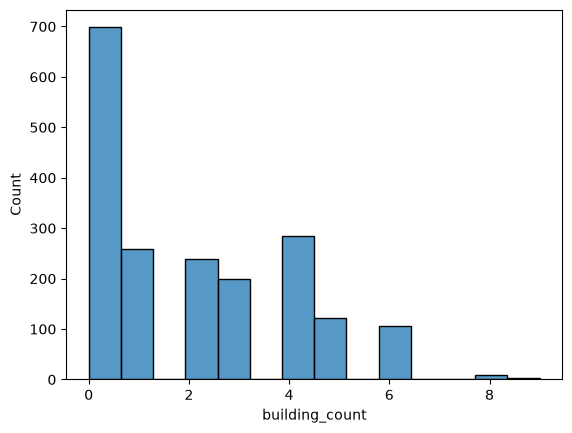

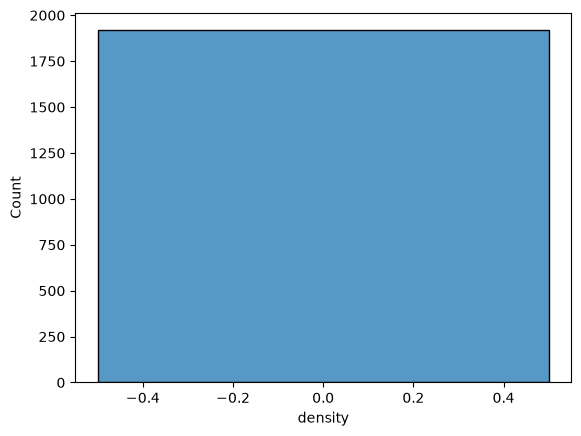

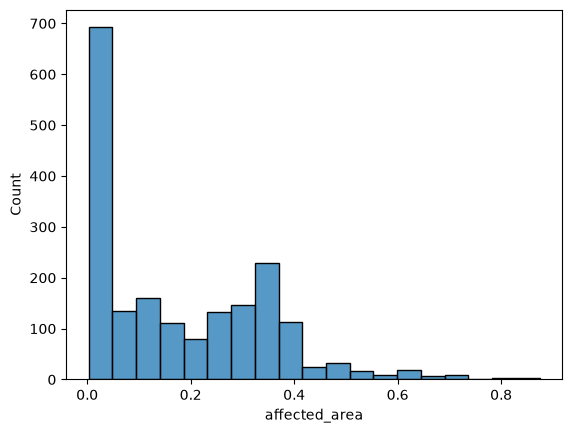

In [11]:
import seaborn as sns
sns.histplot(train_df["building_count"])
plt.show()
sns.histplot(train_df["density"])
plt.show()
sns.histplot(train_df["affected_area"])
plt.show()

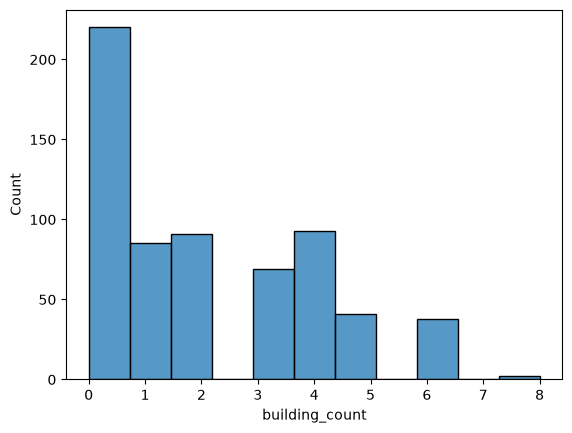

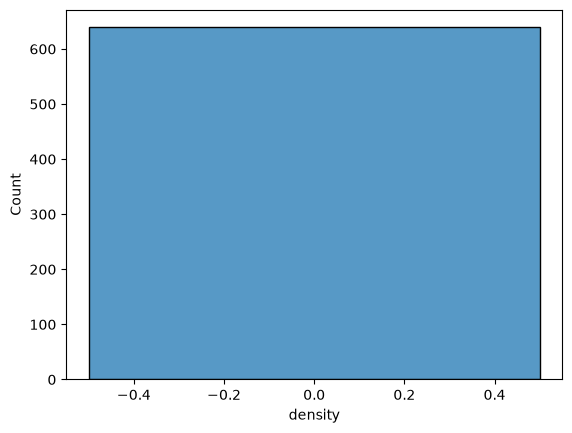

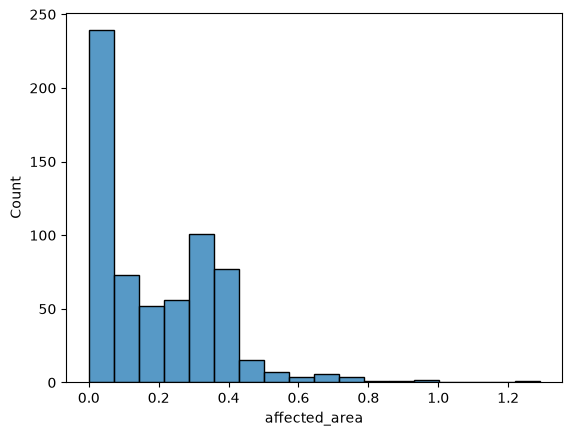

In [13]:
import seaborn as sns
sns.histplot(val_df["building_count"])
plt.show()
sns.histplot(val_df["density"])
plt.show()
sns.histplot(val_df["affected_area"])
plt.show()

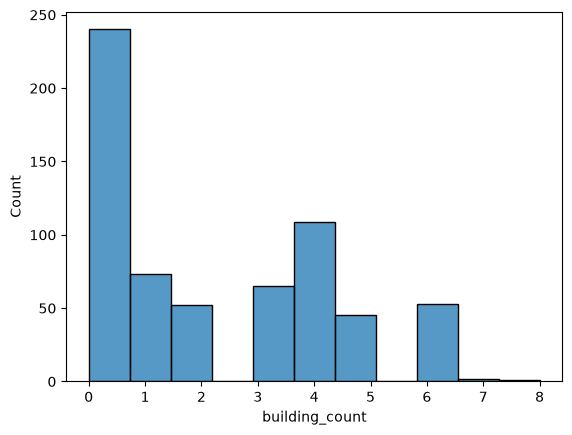

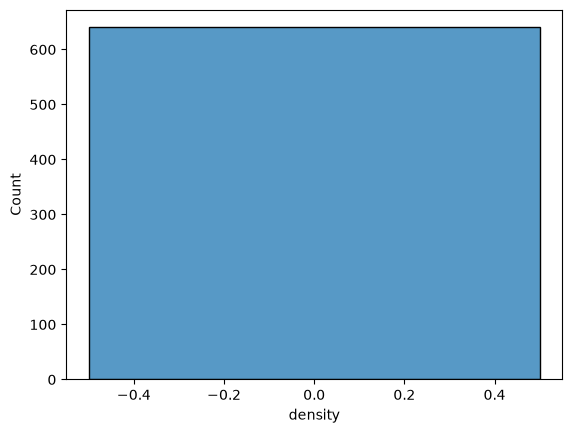

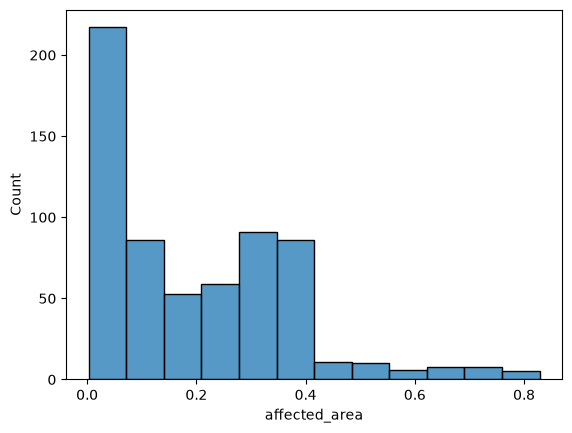

In [12]:
import seaborn as sns
sns.histplot(test_df["building_count"])
plt.show()
sns.histplot(test_df["density"])
plt.show()
sns.histplot(test_df["affected_area"])
plt.show()

In [61]:
# train_df.to_csv("./d2/imputed_train.csv", index=False)
# val_df.to_csv("./d2/imputed_val.csv", index=False)
# test_df.to_csv("./d2/imputed_test.csv", index=False)

In [73]:
# Model 2 regressor part
import seaborn as sns

# EDA the data

train = pd.read_csv("./d2/imputed_train.csv")
val = pd.read_csv("./d2/imputed_val.csv")
test = pd.read_csv("./d2/imputed_test.csv")

# train = train_df.copy()
# val = val_df.copy()
# test = test_df.copy()

# train = pd.DataFrame(train_impute)
# val = pd.DataFrame(val_impute)
# test = pd.DataFrame(test_impute)



<Axes: xlabel='damages_cost', ylabel='Count'>

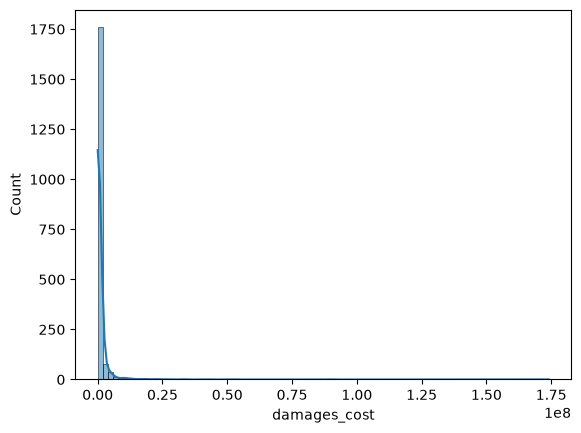

In [74]:
sns.histplot(train["damages_cost"], kde=True)

<Axes: xlabel='damages_cost', ylabel='Count'>

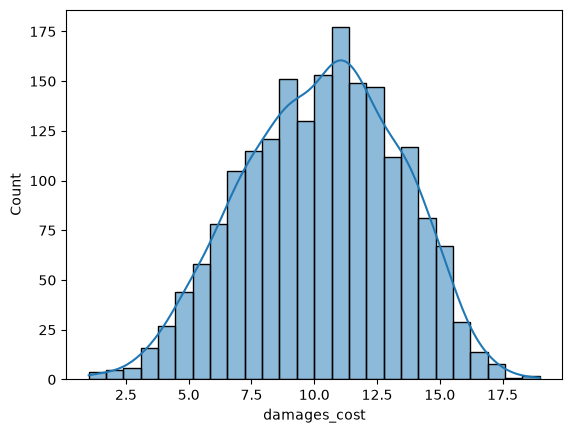

In [75]:
import seaborn as sns
sns.histplot(np.log1p(train["damages_cost"]), kde=True)

In [76]:
np.log1p(train["damages_cost"]).describe()

count    1917.000000
mean       10.270867
std         3.064668
min         1.018847
25%         8.060717
50%        10.440504
75%        12.507592
max        18.974547
Name: damages_cost, dtype: float64

In [77]:
train.describe()

,building_count,density,affected_area,flood_depth_m,flood_duration_hr,rainfall_mm,drainage_capacity_mm,mean_elevation_m,median_building_age,population,elderly_pop_ratio,warning_lead_hours,damages_cost
count,1917.000000,1917.0,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1.917000e+03
mean,1.736568,0.0,0.207369,1.611252,58.400365,206.875222,176.730151,25.488586,45.286072,8.204486,0.189527,20.147679,8.621258e+05
std,1.792464,0.0,0.141243,1.033004,33.151283,105.909392,81.354159,14.330594,17.854363,16.516074,0.058710,12.808679,5.262266e+06
min,0.000000,0.0,-0.000882,0.120000,5.200000,40.000000,60.000000,0.000000,5.000000,0.000000,0.050000,0.000000,1.770000e+00
25%,0.000000,0.0,0.105596,0.700000,28.500000,130.200000,117.000000,14.940000,32.800000,0.000000,0.150200,10.500000,3.166560e+03
50%,1.000000,0.0,0.171848,1.450000,55.000000,183.800000,159.300000,25.050000,45.200000,2.000000,0.189800,19.700000,3.421690e+04
75%,3.000000,0.0,0.262314,2.390000,88.700000,257.100000,219.400000,36.110000,57.700000,9.000000,0.229600,28.900000,2.703812e+05
max,8.000000,0.0,0.772513,3.990000,118.500000,600.000000,400.000000,60.000000,90.000000,225.000000,0.350000,68.400000,1.739967e+08


In [78]:
num_cols = train.select_dtypes(include=["number"]).columns.tolist()
print(num_cols)
print(len(num_cols))

['building_count', 'density', 'affected_area', 'flood_depth_m', 'flood_duration_hr', 'rainfall_mm', 'drainage_capacity_mm', 'mean_elevation_m', 'median_building_age', 'population', 'elderly_pop_ratio', 'warning_lead_hours', 'damages_cost']
13


In [79]:
# Feature Engineering

train["area/flood_depth"] = train["affected_area"] / train["flood_depth_m"]
train["rain_mm/drain_mm"] = train["rainfall_mm"] / train["drainage_capacity_mm"]
train["build_age/pop"] = train["population"] / train["median_building_age"] 

val["area/flood_depth"] = val["affected_area"] / val["flood_depth_m"]
val["rain_mm/drain_mm"] = val["rainfall_mm"] / val["drainage_capacity_mm"]
val["build_age/pop"] = val["population"] / val["median_building_age"] 

test["area/flood_depth"] = test["affected_area"] / test["flood_depth_m"]
test["rain_mm/drain_mm"] = test["rainfall_mm"] / test["drainage_capacity_mm"]
test["build_age/pop"] = test["population"] / test["median_building_age"] 

<Axes: >

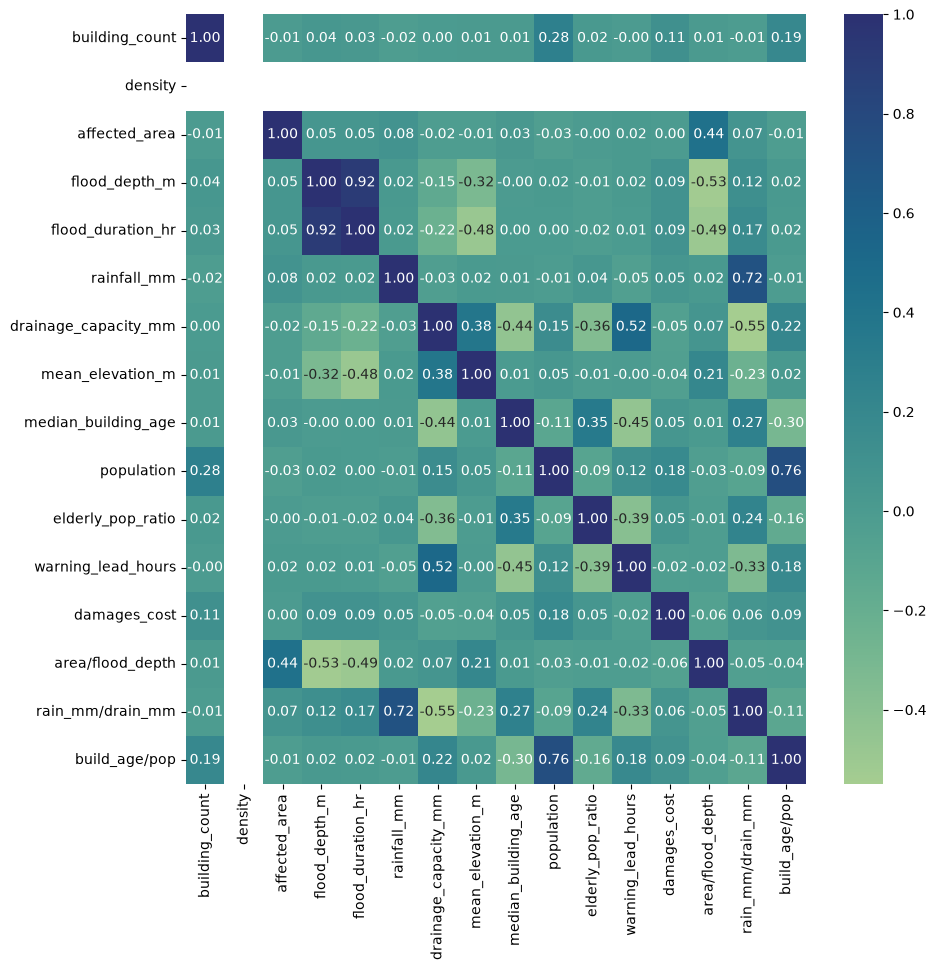

In [80]:
num_cols = train.select_dtypes(include=["number"]).columns.tolist()
corr = train[num_cols].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="crest")

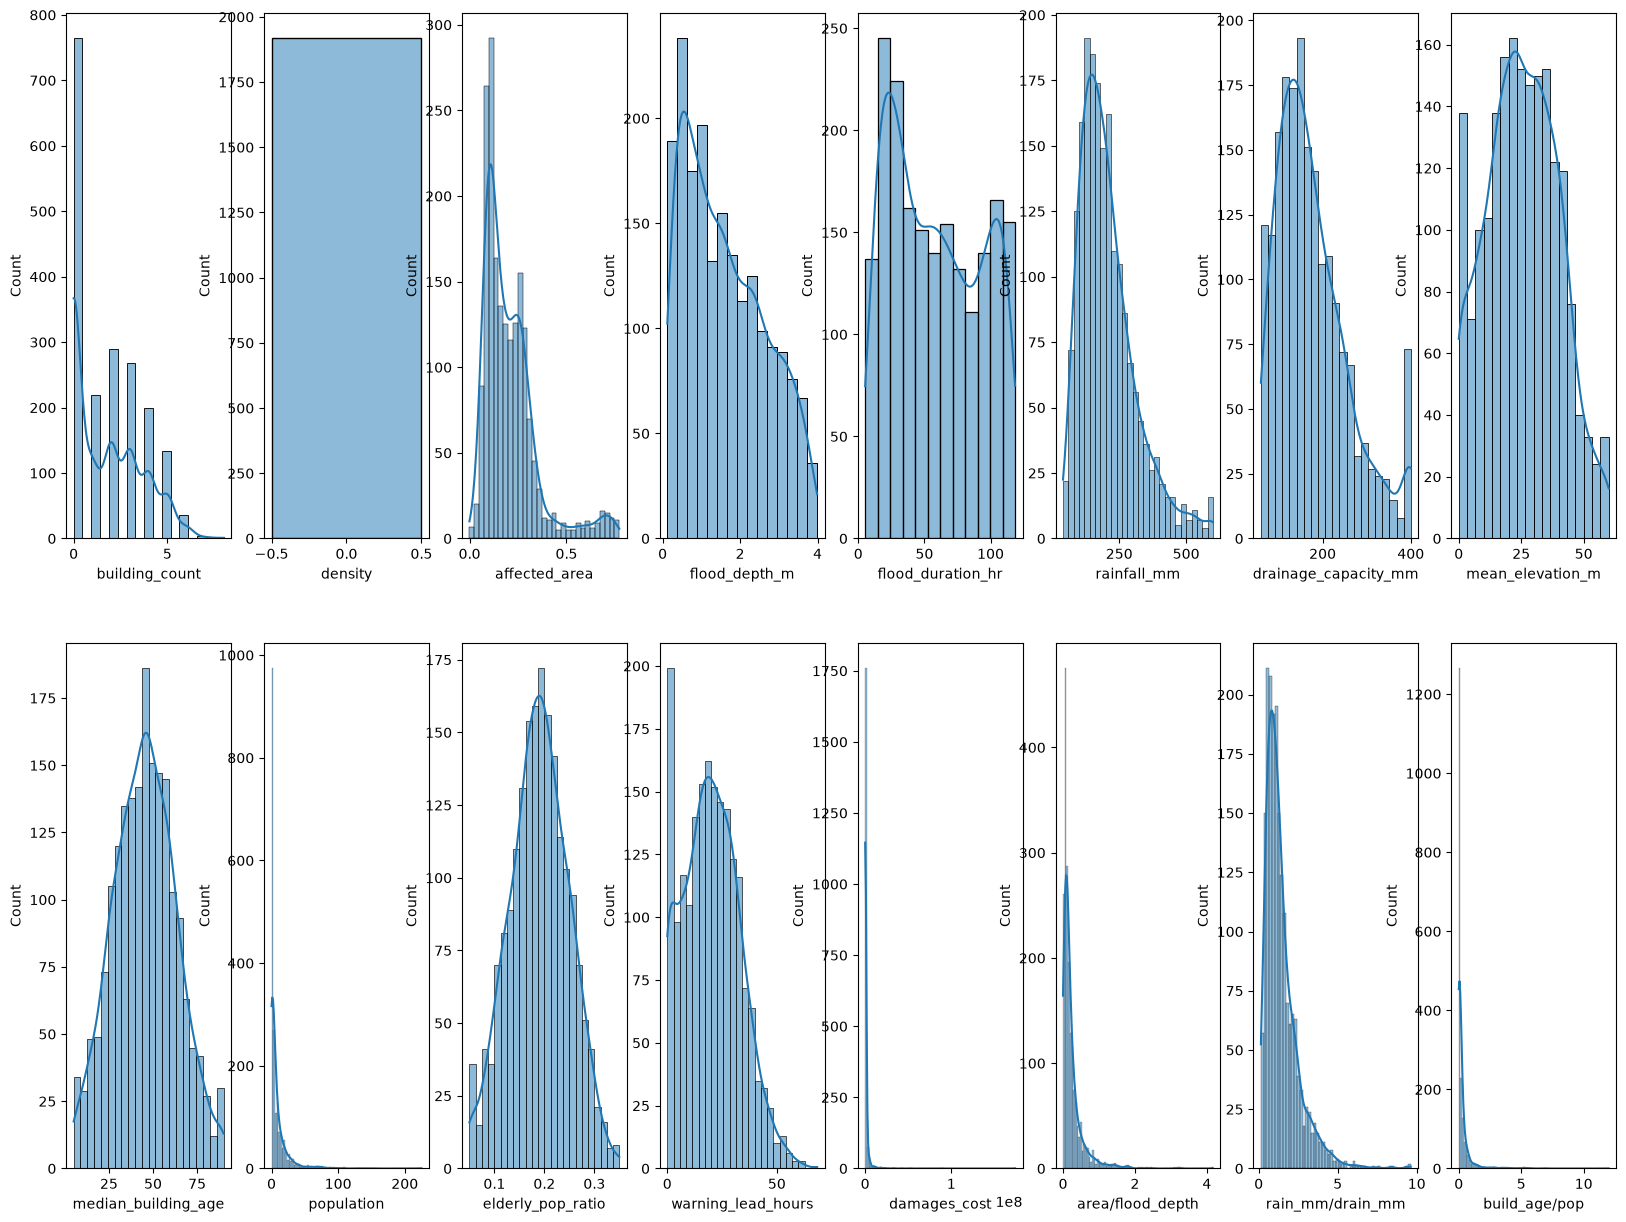

In [81]:
fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(20, 15))

for index, ax in enumerate(axes.flatten()):
    sns.histplot(train[num_cols[index]], kde=True, ax=ax)

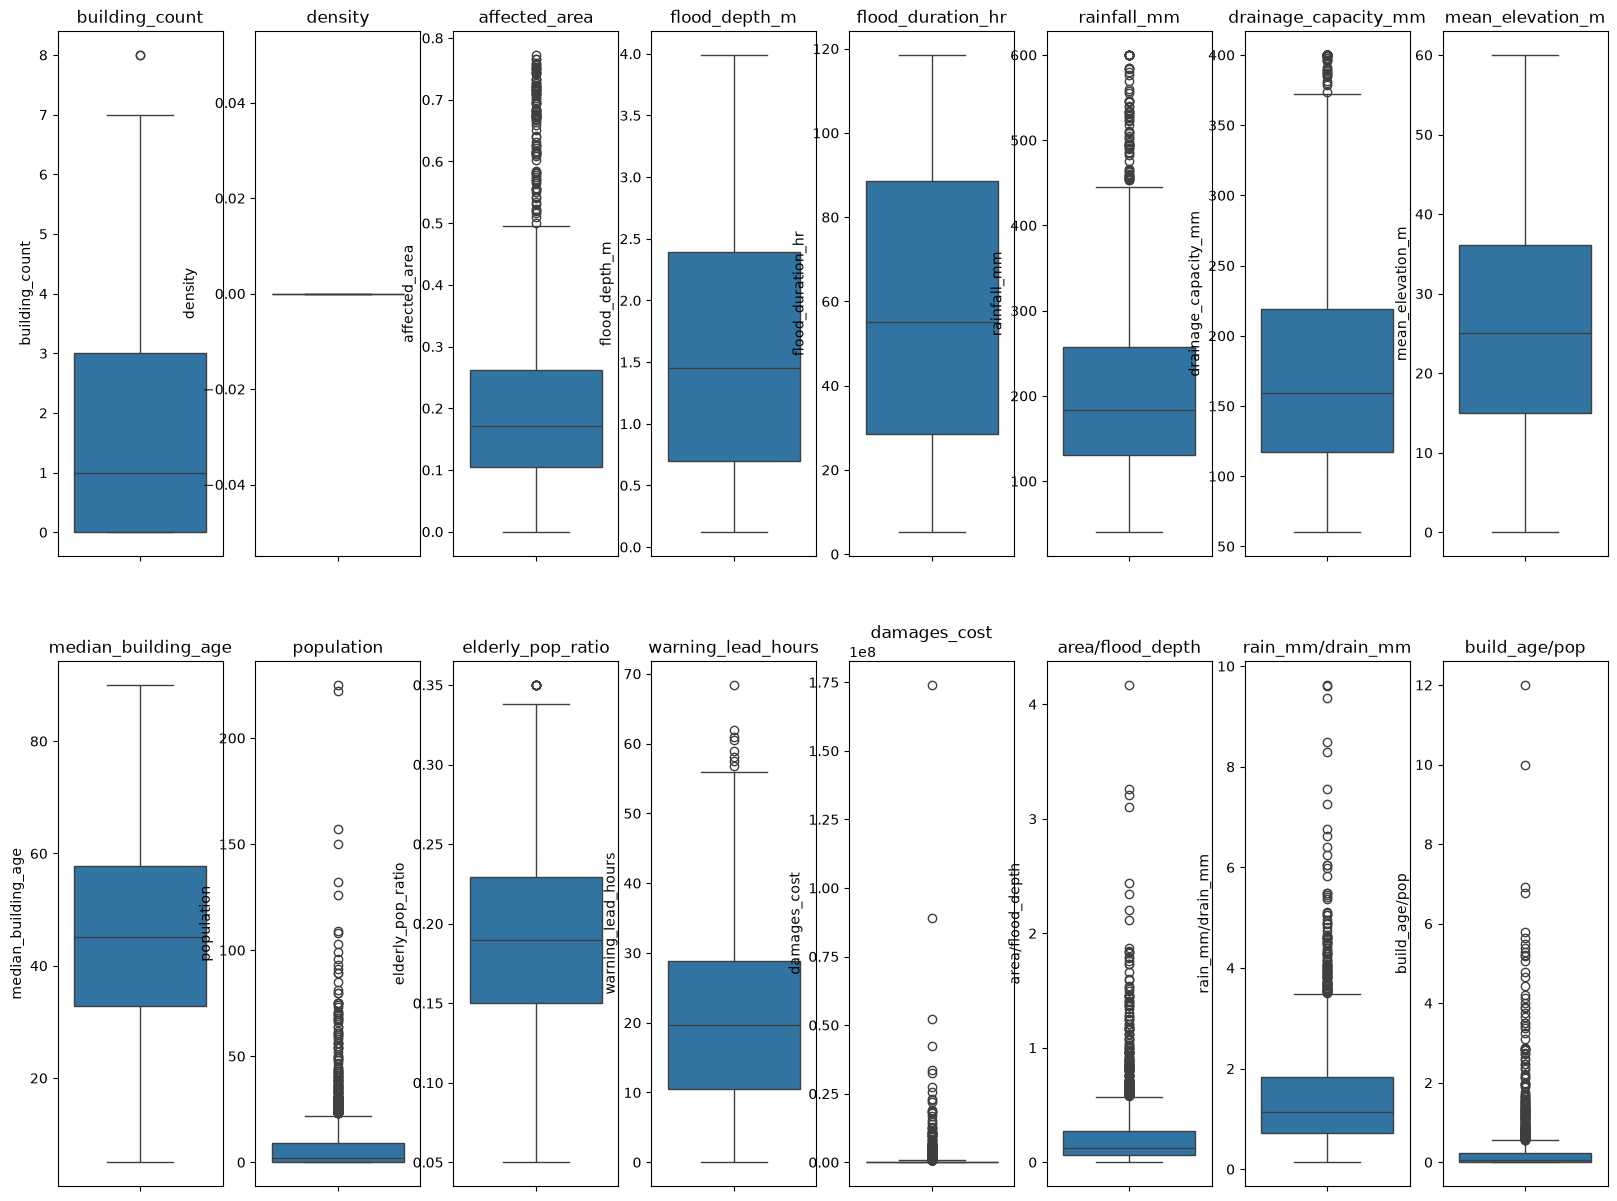

In [82]:
fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(20, 15))

for index, ax in enumerate(axes.flatten()):
    sns.boxplot(train[num_cols[index]], ax=ax)
    ax.set_title(num_cols[index])

In [83]:
# Distribution error columns = ["affected_area", "flood_depth_m", "flood_duration_hr", "rainfall_mm", "drainage_capacity_mm", "mean_elevation_m", "warning_lead_hours"]


right_col = ["building_count", "flood_depth_m", "rainfall_mm", "population", "affected_area", "warning_lead_hours", "drainage_capacity_mm", "area/flood_depth", "rain_mm/drain_mm",
            "build_age/pop"]
left_col = []
for col in num_cols:
    if col in right_col:
   
        train[col] = np.log1p(train[col])
        val[col] = np.log1p(val[col])
        test[col] = np.log1p(test[col])


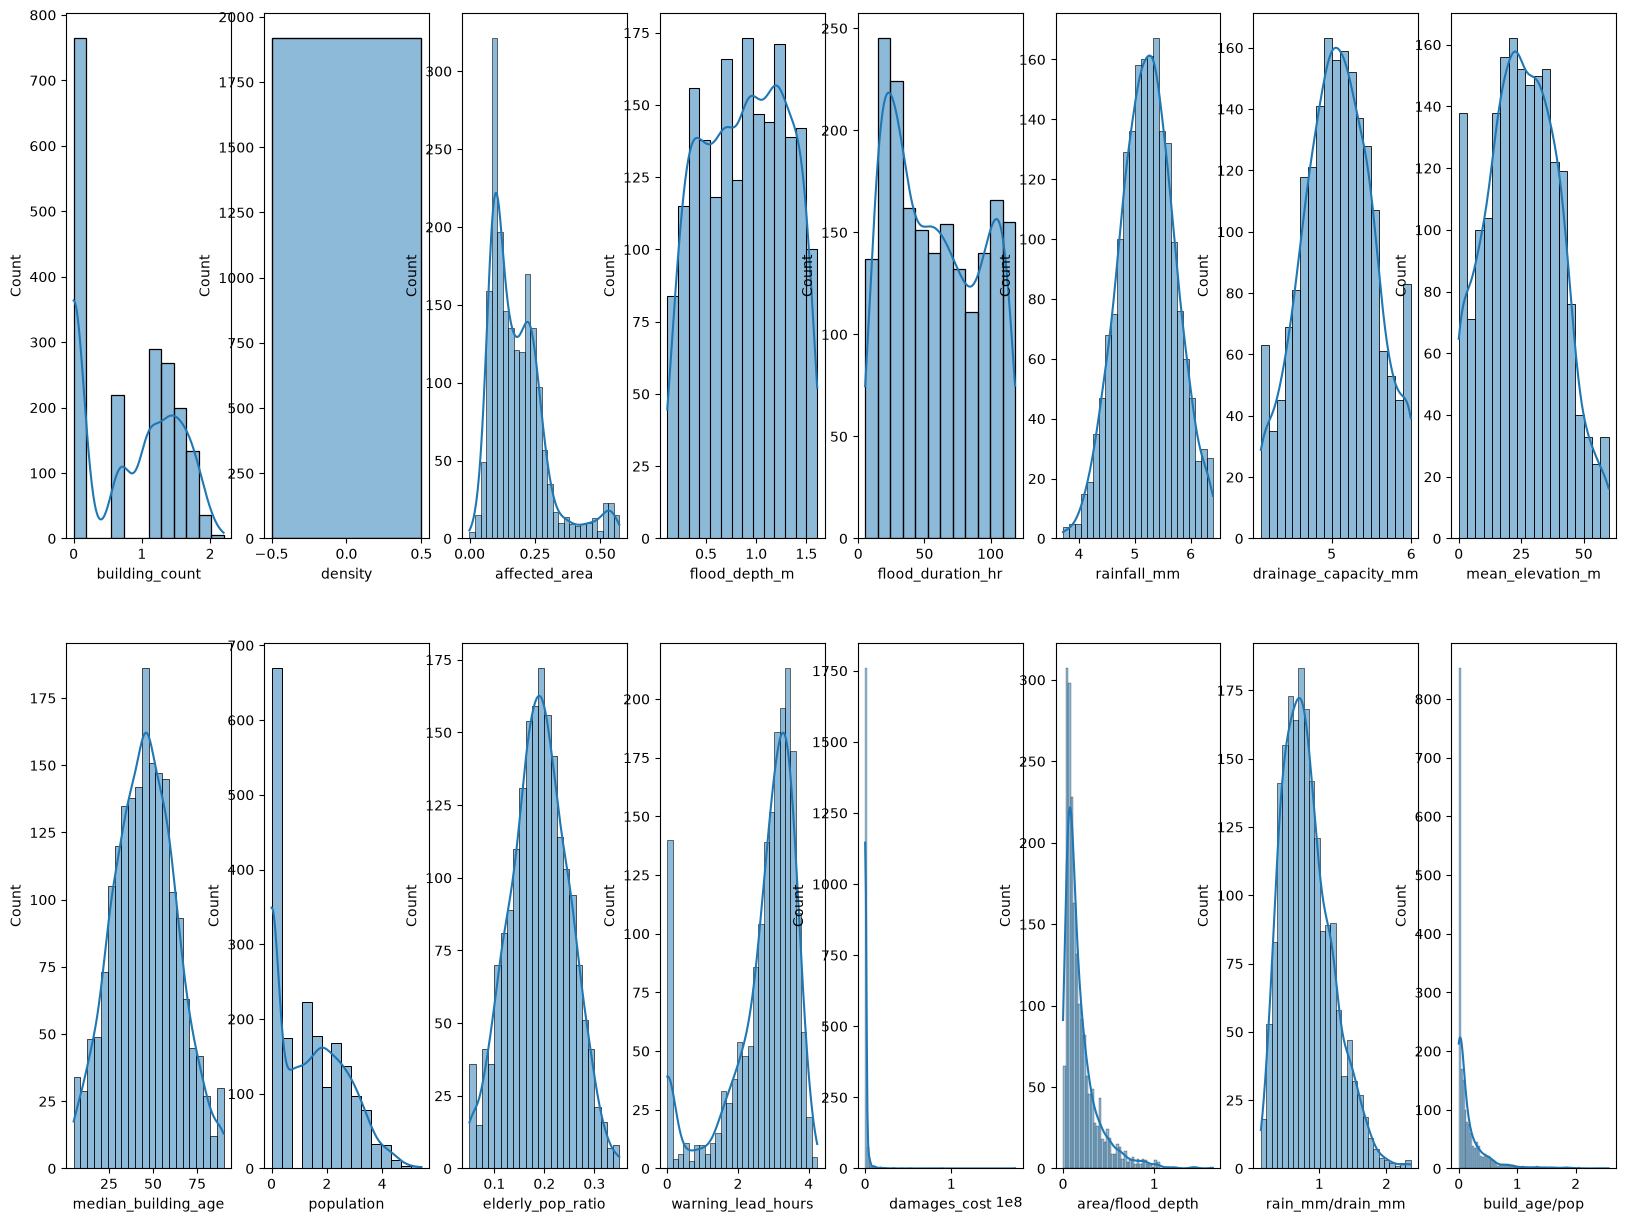

In [85]:
fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(20, 15))

for index, ax in enumerate(axes.flatten()):
    sns.histplot(train[num_cols[index]], kde=True, ax=ax)

In [86]:
train.describe()

,building_count,density,affected_area,flood_depth_m,flood_duration_hr,rainfall_mm,drainage_capacity_mm,mean_elevation_m,median_building_age,population,elderly_pop_ratio,warning_lead_hours,damages_cost,area/flood_depth,rain_mm/drain_mm,build_age/pop
count,1917.000000,1917.0,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1917.000000,1.917000e+03,1917.000000,1917.000000,1917.000000
mean,0.774947,0.0,0.182347,0.879385,58.400365,5.216300,5.079767,25.488586,45.286072,1.350401,0.189527,2.722439,8.621258e+05,0.191075,0.819214,0.170833
std,0.695883,0.0,0.107507,0.405990,33.151283,0.494111,0.450920,14.330594,17.854363,1.268468,0.058710,1.015071,5.262266e+06,0.196942,0.370292,0.299719
min,0.000000,0.0,-0.000883,0.113329,5.200000,3.713572,4.110874,0.000000,5.000000,0.000000,0.050000,0.000000,1.770000e+00,-0.000516,0.129712,0.000000
25%,0.000000,0.0,0.100385,0.530628,28.500000,4.876723,4.770685,14.940000,32.800000,0.000000,0.150200,2.442347,3.166560e+03,0.064499,0.544702,0.000000
50%,0.693147,0.0,0.158582,0.896088,55.000000,5.219274,5.077047,25.050000,45.200000,1.098612,0.189800,3.030134,3.421690e+04,0.119869,0.759939,0.051647
75%,1.386294,0.0,0.232947,1.220830,88.700000,5.553347,5.395444,36.110000,57.700000,2.302585,0.229600,3.397858,2.703812e+05,0.239564,1.041218,0.204794
max,2.197225,0.0,0.572398,1.607436,118.500000,6.398595,5.993961,60.000000,90.000000,5.420535,0.350000,4.239887,1.739967e+08,1.642712,2.363210,2.564949


In [92]:
# Better distribution but can do better
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, RobustScaler
# Class for model

class Regressor(nn.Module):
    def __init__(self, input_dims, output_dims):
        super(Regressor, self).__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dims, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, output_dims)
        )
    def forward(self, x):
        return self.layers(x)

        import torch


class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super(ResidualBlock, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, 32),
            nn.BatchNorm1d(32),
            nn.SiLU(),
            nn.Dropout(0.3),
            nn.Linear(32,16),
            nn.BatchNorm1d(16)
        )

    def forward(self, x):
        # The magic happens here:
        # x = x + self.net(x)
        # TODO: Implement the residual connection
        x = x + self.net(x)
        return x

class ResNetRegressor(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_blocks=3):
        super(ResNetRegressor, self).__init__()
        
        self.initial_projection = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU()
        )

        self.blocks = nn.ModuleList([
            ResidualBlock(hidden_dim),
            ResidualBlock(hidden_dim),
            ResidualBlock(hidden_dim),
            ResidualBlock(hidden_dim)
        ])

        # 3. Final Output Layer
        self.layers = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):

        x = self.initial_projection(x)

        for block in self.blocks:
            x = block(x)
        
        return self.layers(x)

# Example Usage:
# input_dim = X_train_tensor.shape[1]
# model = ResNetRegressor(input_dim, hidden_dim=128, output_dim=1, num_blocks=3)


X_train = train.drop(["damages_cost", "filename", "density"], axis=1)
y_train = train["damages_cost"]

X_val = val.drop(["damages_cost", "filename", "density"], axis=1)
y_val = val["damages_cost"]

X_test = test.drop(["damages_cost", "filename", "density"], axis=1)


# Scaling
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Log the target
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)


# Tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_log.values, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_log.values, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Dataloader and Datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)




In [93]:
from sklearn.metrics import mean_absolute_error, r2_score
from tqdm import tqdm

torch.manual_seed(42)
# Training area
input_dim = X_train_tensor.shape[1]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
output_dim = 1  # Binary classification
model = ResNetRegressor(input_dim, 16, 1).to(device)


# กำหนดฟังก์ชั่นสูญเสียและปรับปรุง (Loss and optimizer)
criterion = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), weight_decay=0.01)

    
epochs = 500
for epoch in range(epochs):
    model.train()
    train_loss = []
    train_scores = []
    for x, y in tqdm(train_loader, desc=f"Epoch: {epoch}"):
        opt.zero_grad()
        x = x.to(device)
        y = y.to(device)

        outputs_log = model(x)
        loss = criterion(outputs_log, y.view(-1, 1))

        l2_norm = sum(p.pow(2).sum() for p in model.parameters())
        loss += 0.01 * l2_norm
        loss.backward()
        opt.step()
        train_loss.append(loss.item())

        pred_log = outputs_log.detach().cpu().numpy()
        true_log = y.detach().cpu().numpy()

        log_r2 = 1 - ((np.mean((pred_log - true_log) ** 2))) / np.var(true_log) ** 2
        log_mae = np.mean(np.abs(pred_log - true_log))
        k = 10.0
        y = 1.3
        e = 1.1
        a = -1

        s_log_mae = (1/(1+np.exp(k*(log_mae-y)))) * np.exp(-a*(log_mae - e))


        # print(f"log_mae: {log_mae}")
        # print(f"s_log_mae: {s_log_mae}")
        # print(f"log_r2: {log_r2}")

        score = 0.7 * s_log_mae + 0.3 * log_r2
        train_scores.append(score)
        

    model.eval()
    val_loss = []
    val_scores = []
    with torch.no_grad():
        for x, y in tqdm(val_loader, desc=f"Epoch: {epoch}"):
            opt.zero_grad()
            x = x.to(device)
            y = y.to(device)
            outputs_log = model(x)
            loss = criterion(outputs_log, y.view(-1, 1))
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss += 0.01 * l2_norm
            # For debugging
            # print(y.mean())
            # print(outputs_log.mean())
            # print(outputs_log.var())
            # print(y.var())

            if (epoch % 100) == 0:
                print("Target mean", y.mean())
                print("Prediction mean", outputs_log.mean())
                print("Prediction variance", outputs_log.var())
                print("Target variance", y.var())

            pred_log = outputs_log.detach().cpu().numpy()
            true_log = y.detach().cpu().numpy()

            pred_ori = np.exp(pred_log) - 1
            true_ori = np.exp(true_log) - 1
    
            log_r2 = 1 - ((np.mean((pred_log - true_log) ** 2))) / np.var(true_log) ** 2
            log_mae = np.mean(np.abs(pred_log - true_log))
            k = 10.0
            y = 1.3
            e = 1.1
            a = -1
    
            s_log_mae = (1/(1+np.exp(k*(log_mae-y)))) * np.exp(-a*(log_mae - e))


            # print(f"log_mae: {log_mae}")
            # print(f"s_log_mae: {s_log_mae}")
            # print(f"log_r2: {log_r2}")
            score = 0.7 * s_log_mae + 0.3 * log_r2

            val_loss.append(loss.item())
            val_scores.append(score)


    # if current_val_score > best_score:
    #     best_score = current_val_score

    #     torch.save(model.state_dict(), checkpoint_path)
    #     print(f"Save new checkpoint at {current_val_score}")
    
    if epoch % 5 == 0:
        print(f"Epoch {epoch}: Train Loss: {sum(train_loss) / len(train_loss)}")
        print(f"Val Loss: {sum(val_loss)/len(val_loss)}")
        print(f"Train score: {sum(train_scores) / len(train_scores)}")
        print(f"Val score: {sum(val_scores) / len(val_scores)}")


Epoch: 0:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipykernel_2430858/3302959882.py:47: RuntimeWarning: overflow encountered in exp
  s_log_mae = (1/(1+np.exp(k*(log_mae-y)))) * np.exp(-a*(log_mae - e))
Epoch: 0: 100%|██████████| 20/20 [00:00<00:00, 371.44it/s]


Target mean tensor(10.9809, device='cuda:0')
Prediction mean tensor(2.1096, device='cuda:0')
Prediction variance tensor(4.4752, device='cuda:0')
Target variance tensor(6.9310, device='cuda:0')
Target mean tensor(10.1852, device='cuda:0')
Prediction mean tensor(1.2966, device='cuda:0')
Prediction variance tensor(4.8682, device='cuda:0')
Target variance tensor(7.5849, device='cuda:0')
Target mean tensor(10.2893, device='cuda:0')
Prediction mean tensor(1.2728, device='cuda:0')
Prediction variance tensor(4.0334, device='cuda:0')
Target variance tensor(14.9485, device='cuda:0')
Target mean tensor(10.4397, device='cuda:0')
Prediction mean tensor(1.6934, device='cuda:0')
Prediction variance tensor(3.4554, device='cuda:0')
Target variance tensor(7.5230, device='cuda:0')
Target mean tensor(10.5092, device='cuda:0')
Prediction mean tensor(1.6157, device='cuda:0')
Prediction variance tensor(2.2778, device='cuda:0')
Target variance tensor(9.0601, device='cuda:0')
Target mean tensor(10.7930, device

Epoch: 5: 100%|██████████| 20/20 [00:00<00:00, 681.89it/s]


Epoch 5: Train Loss: 6.794561274846395
Val Loss: 5.561499285697937
Train score: 0.23739030957221985
Val score: 0.2399938851594925


Epoch: 10: 100%|██████████| 20/20 [00:00<00:00, 682.96it/s]


Epoch 10: Train Loss: 5.765175441900889
Val Loss: 5.189507484436035
Train score: 0.23683862388134003
Val score: 0.2375643253326416


... (191 outputs left out)

Epoch 490: Train Loss: 2.927670754988988
Val Loss: 2.831459802389145
Train score: 0.235874205827713
Val score: 0.2358814924955368


Epoch: 495: 100%|██████████| 20/20 [00:00<00:00, 677.40it/s]


Epoch 495: Train Loss: 2.992588633298874
Val Loss: 2.8209985852241517
Train score: 0.23626211285591125
Val score: 0.23824867606163025


Epoch: 499: 100%|██████████| 20/20 [00:00<00:00, 684.32it/s]


In [94]:
path = "./less_overfitting.pth"
torch.save(model.state_dict(), path)

In [95]:
# Evaluation model

from tqdm import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_model = ResNetRegressor(input_dim, 16, 1).to(device)
test_model.load_state_dict(torch.load(path, weights_only=True))


model.eval()

predictions = []

with torch.no_grad():
    for x in tqdm(test_loader):
        x = x[0].to(device)
        opt.zero_grad()
        outputs = model(x)

        pred = outputs.detach().cpu().numpy().squeeze()
        predictions.extend(pred)
        

predictions = np.exp(predictions) + 1

        
        
    


100%|██████████| 20/20 [00:00<00:00, 1770.20it/s]


In [96]:

submission = pd.DataFrame({
    "filename": test["filename"],
    "damages_cost": predictions
})

<Axes: xlabel='damages_cost', ylabel='Count'>

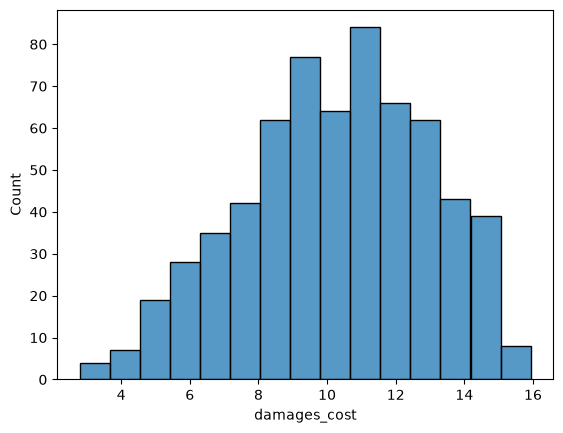

In [97]:
sns.histplot(np.log1p(submission["damages_cost"]))

<Axes: xlabel='damages_cost', ylabel='Count'>

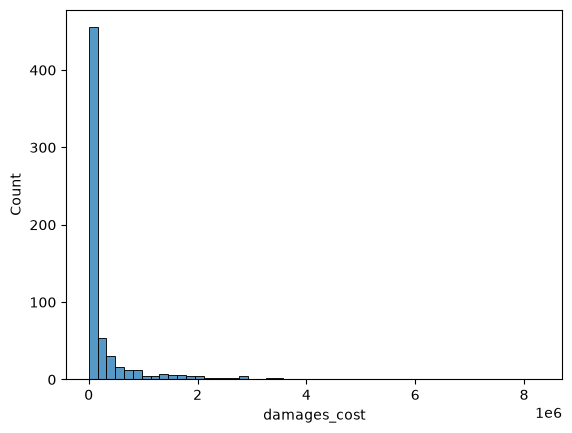

In [98]:
sns.histplot(submission["damages_cost"])

In [99]:
submission.to_csv("./submission_day2/submission_final.csv", index=False)

In [100]:
submission.describe()

,damages_cost
count,6.400000e+02
mean,3.382061e+05
std,8.633850e+05
min,1.531379e+01
25%,4.104603e+03
50%,3.374836e+04
75%,2.237242e+05
max,8.285793e+06
